# ⚡ EV Charging Infrastructure — Full EDA
**End-to-end exploratory data analysis walkthrough**

Datasets used:
- `charging_station.csv` — 242K+ individual stations
- `world_summary.csv` — country-level metrics
- `ev_models.csv` — 129 BEV model catalogue
- `charging_station_ml.csv` — city-level aggregates

In [1]:
import warnings, json
import numpy  as np
import pandas as pd
import matplotlib.pyplot  as plt
import matplotlib.patches as mpatches
import seaborn            as sns
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})

BASE = Path.cwd().parent
DATA = BASE / 'data'
OUT  = BASE / 'dashboard' / 'images' / 'charts'
OUT.mkdir(parents=True, exist_ok=True)

print('Paths ready. BASE:', BASE)

Paths ready. BASE: d:\final_project\ev-charging-infrastructure-analysis


## 1. Load Datasets

In [2]:
cs      = pd.read_csv(DATA / 'charging_station.csv')
cs_ml   = pd.read_csv(DATA / 'charging_station_ml.csv')
country = pd.read_csv(DATA / 'country_summary.csv')
world   = pd.read_csv(DATA / 'world_summary.csv')
ev      = pd.read_csv(DATA / 'ev_models.csv')

for name, df in [('charging_station', cs), ('charging_station_ml', cs_ml),
                  ('country_summary', country), ('world_summary', world), ('ev_models', ev)]:
    print(f'{name:<25} {df.shape[0]:>7,} rows x {df.shape[1]} cols')

charging_station          242,417 rows x 11 cols
charging_station_ml        58,642 rows x 17 cols
country_summary               121 rows x 6 cols
world_summary                 121 rows x 12 cols
ev_models                     128 rows x 8 cols


## 2. Data Cleaning

In [3]:
# charging_station
cs['power_kw'] = cs['power_kw'].fillna(0)
cs['power_class'] = cs['power_class'].replace('UNKNOWN', 'Unspecified')
cs['city'] = cs['city'].str.strip().replace('Unknown City', 'Unknown')
before = len(cs)
cs.drop_duplicates(subset=['id'], inplace=True)
print(f'Duplicates removed: {before - len(cs):,}')
p99 = cs['power_kw'].quantile(0.99)
cs['power_kw_capped'] = cs['power_kw'].clip(upper=p99)

# world_summary
world['max_power_kw']    = world['max_power_kw'].fillna(world['max_power_kw'].median())
world['median_power_kw'] = world['median_power_kw'].fillna(world['median_power_kw'].median())
world['ports_per_station'] = (world['port_count'] / world['station_count']).round(2)
world['fast_station_share_pct'] = (world['fast_station_share'] * 100).round(2)
world['ultra_fast_share'] = (world['dc_ultra_station_count'] / world['station_count']).round(4)

print('Cleaning done ✔')

Duplicates removed: 0
Cleaning done ✔


## 3. EDA — Power Class Distribution

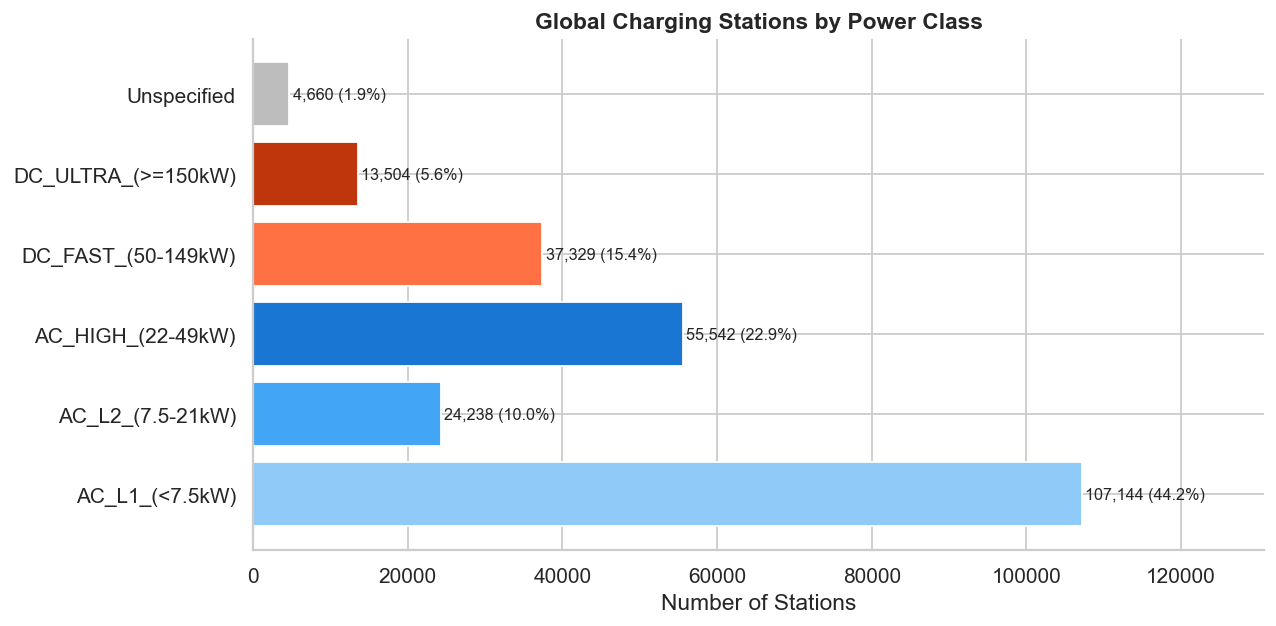

In [4]:
pc_order  = ['AC_L1_(<7.5kW)','AC_L2_(7.5-21kW)','AC_HIGH_(22-49kW)',
             'DC_FAST_(50-149kW)','DC_ULTRA_(>=150kW)','Unspecified']
pc_counts = cs['power_class'].value_counts().reindex(pc_order, fill_value=0)
colors_pc = ['#90CAF9','#42A5F5','#1976D2','#FF7043','#BF360C','#BDBDBD']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(pc_counts.index, pc_counts.values, color=colors_pc, edgecolor='white')
ax.set_xlabel('Number of Stations')
ax.set_title('Global Charging Stations by Power Class', fontweight='bold')
for bar, val in zip(bars, pc_counts.values):
    ax.text(bar.get_width()+500, bar.get_y()+bar.get_height()/2,
            f'{val:,} ({val/len(cs)*100:.1f}%)', va='center', fontsize=9)
ax.set_xlim(0, pc_counts.max()*1.22)
plt.tight_layout()
plt.savefig(OUT / '01_power_class.png', bbox_inches='tight')
plt.show()

## 4. Top 15 Countries by Station Count

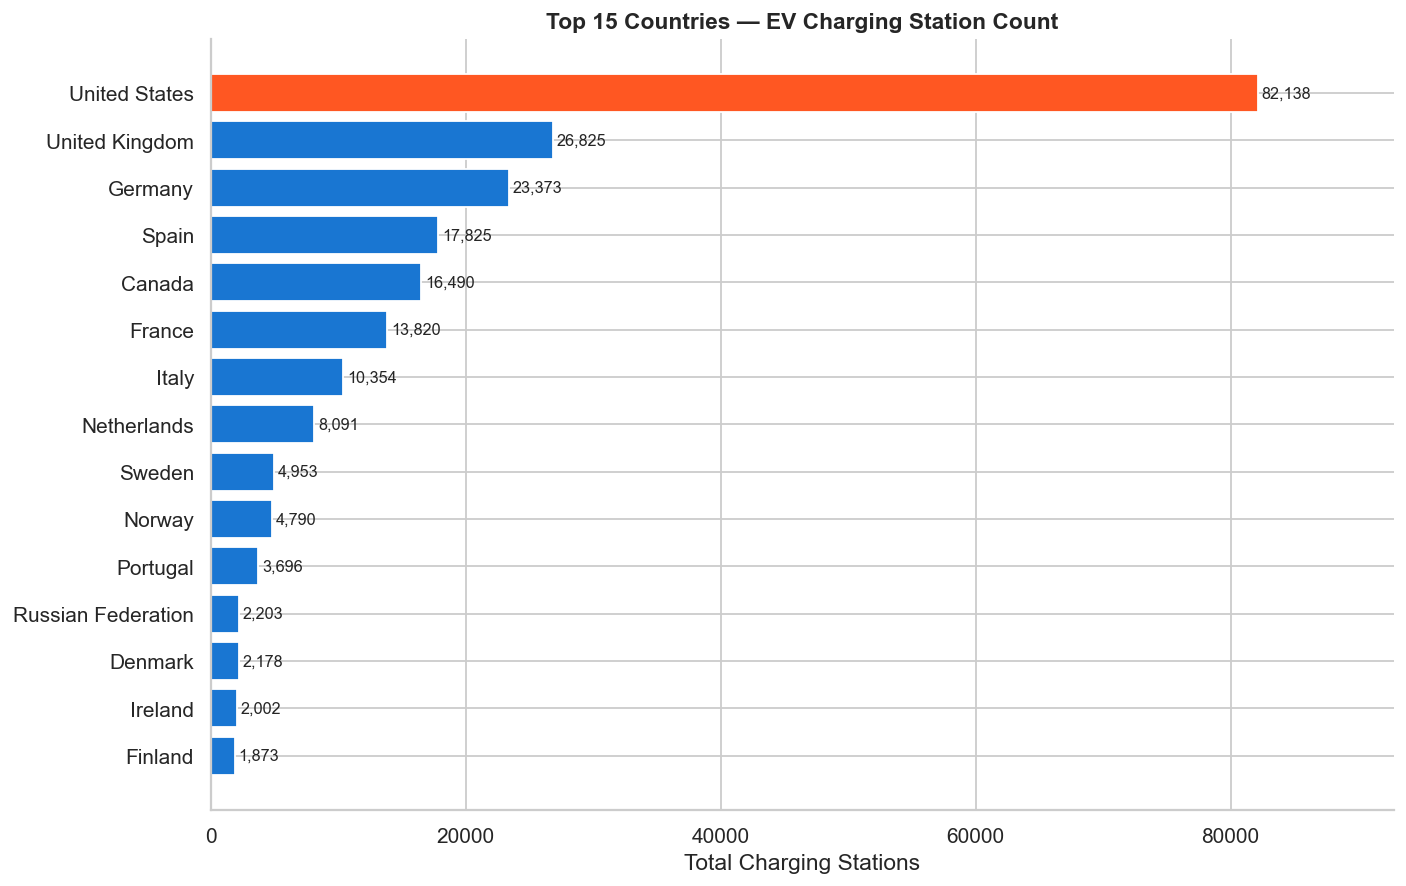

In [5]:
top15 = world.nlargest(15, 'station_count').sort_values('station_count')
bar_colors = ['#FF5722' if c=='United States' else '#1976D2' for c in top15['country']]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(top15['country'], top15['station_count'], color=bar_colors, edgecolor='white')
ax.set_xlabel('Total Charging Stations')
ax.set_title('Top 15 Countries — EV Charging Station Count', fontweight='bold')
for bar, val in zip(bars, top15['station_count']):
    ax.text(bar.get_width()+300, bar.get_y()+bar.get_height()/2, f'{val:,}', va='center', fontsize=9)
ax.set_xlim(0, top15['station_count'].max()*1.13)
plt.tight_layout()
plt.savefig(OUT / '04_top15_countries.png', bbox_inches='tight')
plt.show()

## 5. EV Readiness Score

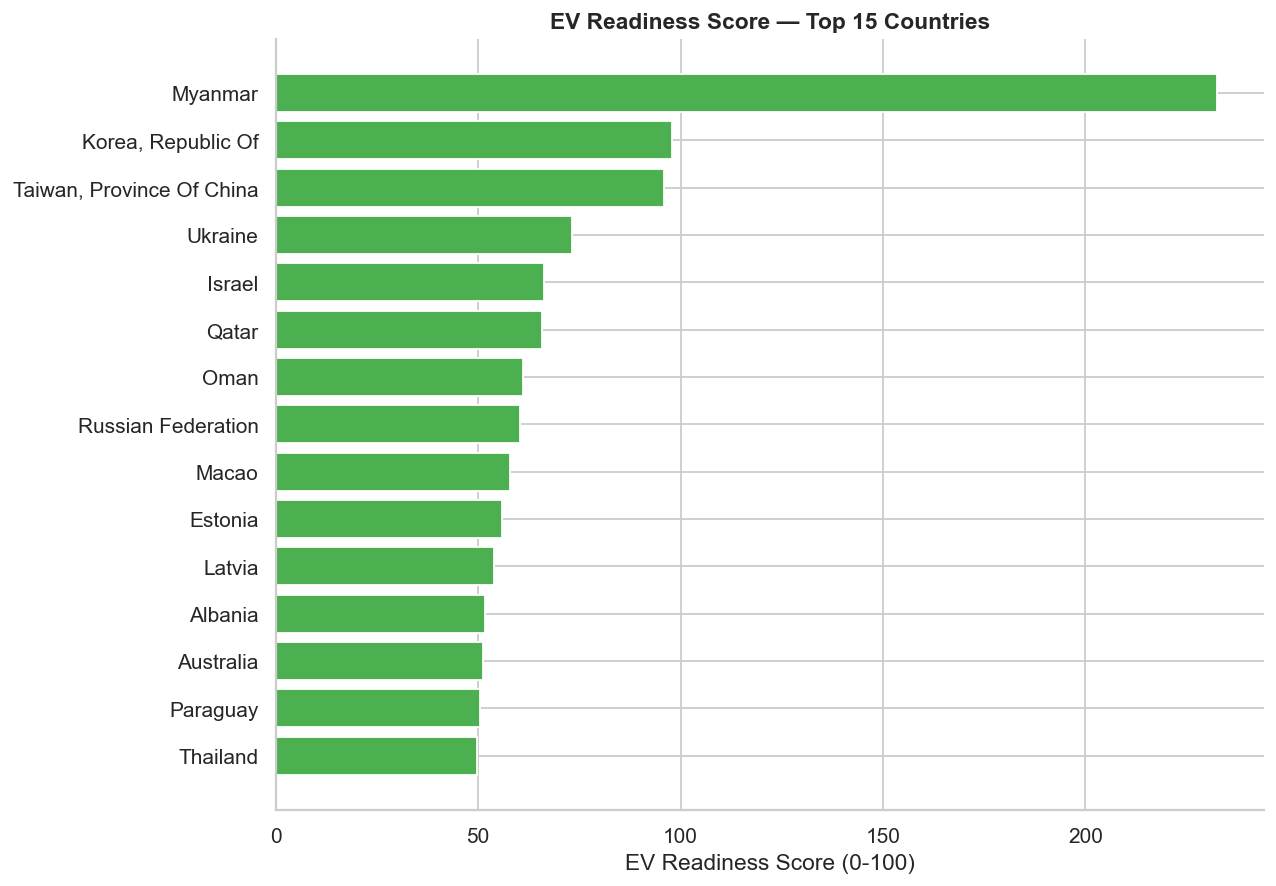

                  country  station_count  fast_station_share  readiness_score
                  Myanmar              1            1.000000           232.45
       Korea, Republic Of            161            1.000000            97.98
Taiwan, Province Of China            162            0.932099            95.97
                  Ukraine            563            0.891652            73.14
                   Israel            295            0.935593            66.18
                    Qatar              4            1.000000            65.69
                     Oman             22            0.863636            60.99
       Russian Federation           2203            0.699955            60.21
                    Macao              2            1.000000            57.88
                  Estonia            169            0.923077            55.85


In [6]:
max_st = world['station_count'].max()
world['readiness_score'] = (
    0.40 * (np.log1p(world['station_count']) / np.log1p(max_st)) +
    0.30 * world['fast_station_share'] +
    0.30 * (world['median_power_kw'] / 150)
).round(4) * 100

top15r = world.nlargest(15, 'readiness_score').sort_values('readiness_score')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top15r['country'], top15r['readiness_score'], color='#4CAF50', edgecolor='white')
ax.set_xlabel('EV Readiness Score (0-100)')
ax.set_title('EV Readiness Score — Top 15 Countries', fontweight='bold')
plt.tight_layout()
plt.show()

print(world.nlargest(10,'readiness_score')[['country','station_count','fast_station_share','readiness_score']].to_string(index=False))

## 6. EV Model Analysis

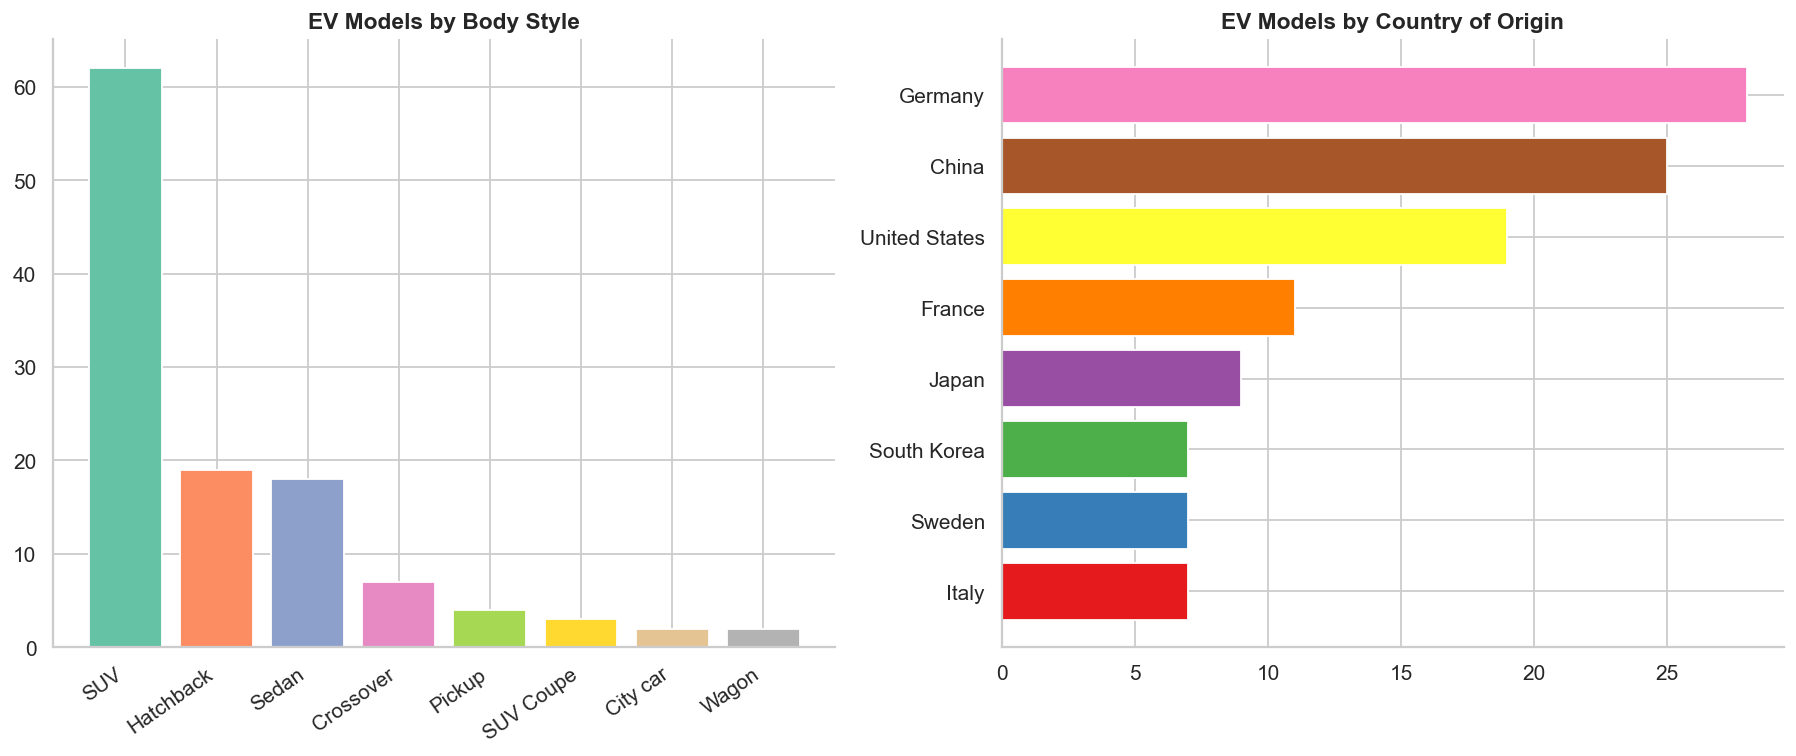

In [7]:
country_map = {'US':'United States','DE':'Germany','CN':'China','KR':'South Korea',
               'JP':'Japan','FR':'France','IT':'Italy','SE':'Sweden','UK':'United Kingdom'}
ev['origin_clean'] = ev['origin_country'].map(country_map).fillna(ev['origin_country'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
body = ev['body_style'].value_counts().head(8)
axes[0].bar(body.index, body.values, color=sns.color_palette('Set2', 8), edgecolor='white')
axes[0].set_xticklabels(body.index, rotation=35, ha='right')
axes[0].set_title('EV Models by Body Style', fontweight='bold')

origin = ev['origin_clean'].value_counts().head(8)
axes[1].barh(origin.index[::-1], origin.values[::-1], color=sns.color_palette('Set1',8), edgecolor='white')
axes[1].set_title('EV Models by Country of Origin', fontweight='bold')

plt.tight_layout()
plt.savefig(OUT / '09_ev_body_origin.png', bbox_inches='tight')
plt.show()

## 7. BEV Model Launch Trend

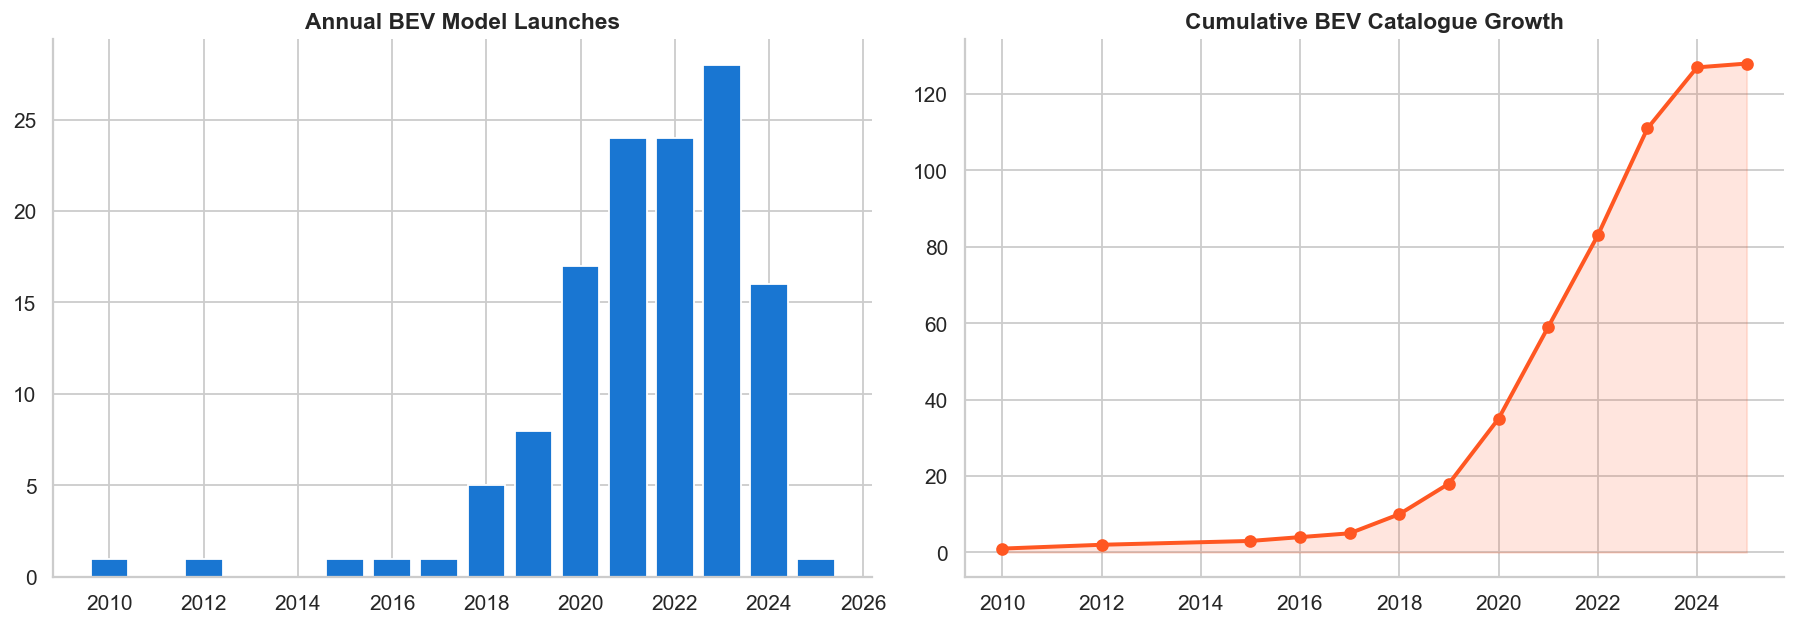

In [8]:
launch = ev.groupby('first_year').size().reset_index(name='models')
launch['cumulative'] = launch['models'].cumsum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(launch['first_year'], launch['models'], color='#1976D2', edgecolor='white')
axes[0].set_title('Annual BEV Model Launches', fontweight='bold')

axes[1].plot(launch['first_year'], launch['cumulative'], marker='o', color='#FF5722', lw=2.2)
axes[1].fill_between(launch['first_year'], launch['cumulative'], alpha=0.15, color='#FF5722')
axes[1].set_title('Cumulative BEV Catalogue Growth', fontweight='bold')

plt.tight_layout()
plt.savefig(OUT / '10_ev_launch_trend.png', bbox_inches='tight')
plt.show()

## 8. Next Steps

Run the ML pipeline:
```bash
python scripts/feature_engineering.py
python scripts/model_training.py
streamlit run dashboard/app.py
```